### Piyasa Dengesi ve Vergi Yükü Modeli

Bu notebook, doğrusal talep ve arz eğrileriyle tanımlanan rekabetçi bir piyasayı modeller. Model şu soruları yanıtlar:

1. Piyasa hangi fiyat ve miktarda dengeye gelir?
2. Denge noktasında talep ve arz ne kadar esnektir?
3. Tüketici ve üretici bu piyasadan ne kadar fayda (refah) elde eder?
4. Birim başına bir vergi konduğunda vergiyi **gerçekte** kim öder ve toplumun refah kaybı ne kadardır?

**Model denklemleri** (fiyat, miktarın fonksiyonu olarak):

$$\text{Ters talep: } P = \alpha - \beta Q \qquad\qquad \text{Ters arz: } P = \gamma + \delta Q$$

| Sembol | Anlamı |
|---|---|
| $\alpha$ | Tüketicinin ödemeye razı olduğu en yüksek fiyat |
| $\beta$ | Talep eğrisinin eğimi (büyüdükçe talep fiyata daha az duyarlı) |
| $\gamma$ | Üreticinin satış yapmaya razı olduğu en düşük fiyat |
| $\delta$ | Arz eğrisinin eğimi (büyüdükçe arz fiyata daha az duyarlı) |
| $t$ | Satılan her birim için alınan vergi |

**Temel sonuçlar:**

- Denge: $Q^* = \dfrac{\alpha - \gamma}{\beta + \delta}$, $\quad P^* = \alpha - \beta Q^*$
- Tüketici fazlası: $TF = \tfrac{1}{2}\beta Q^{*2}$, $\quad$ Üretici fazlası: $ÜF = \tfrac{1}{2}\delta Q^{*2}$
- Vergi sonrası miktar: $Q_t = \dfrac{\alpha - \gamma - t}{\beta + \delta}$
- Verginin alıcıya düşen payı: $\dfrac{\beta}{\beta + \delta}$, $\quad$ satıcıya düşen payı: $\dfrac{\delta}{\beta + \delta}$
- Ölü ağırlık kaybı: $ÖAK = \tfrac{1}{2}\, t\,(Q^* - Q_t)$
- Vergi gelirini en üst düzeye çıkaran oran: $t_{max} = \dfrac{\alpha - \gamma}{2}$

In [1]:
import math
from dataclasses import dataclass


@dataclass(frozen=True)
class Equilibrium:
    """Vergisiz piyasa dengesinin sonuçları."""

    quantity: float            # Denge miktarı (Q*)
    price: float               # Denge fiyatı (P*)
    consumer_surplus: float    # Tüketici fazlası
    producer_surplus: float    # Üretici fazlası
    demand_elasticity: float   # Talebin fiyat esnekliği (denge noktasında)
    supply_elasticity: float   # Arzın fiyat esnekliği (denge noktasında)

    @property
    def total_surplus(self) -> float:
        """Toplam refah = tüketici fazlası + üretici fazlası."""
        return self.consumer_surplus + self.producer_surplus


@dataclass(frozen=True)
class TaxIncidence:
    """Birim vergi sonrası piyasanın durumu."""

    tax: float                 # Birim başına vergi (t)
    quantity: float            # Vergi sonrası miktar (Qt)
    buyer_price: float         # Alıcının ödediği fiyat (Pb)
    seller_price: float        # Satıcının eline geçen fiyat (Ps = Pb - t)
    consumer_surplus: float
    producer_surplus: float
    tax_revenue: float         # Devletin vergi geliri
    deadweight_loss: float     # Ölü ağırlık kaybı (kimsenin kazanamadığı refah)
    buyer_share: float         # Vergi yükünün alıcıya düşen oranı
    seller_share: float        # Vergi yükünün satıcıya düşen oranı

    @property
    def total_surplus(self) -> float:
        """Vergi sonrası toplam refah = TF + ÜF + vergi geliri."""
        return self.consumer_surplus + self.producer_surplus + self.tax_revenue


@dataclass(frozen=True)
class LinearMarket:
    """
    Doğrusal ters talep ve ters arz fonksiyonlarıyla tanımlanan rekabetçi piyasa.

        Ters talep: P = alpha - beta * Q
        Ters arz:   P = gamma + delta * Q

    Args:
        alpha (float): Talep eğrisinin fiyat eksenini kestiği nokta.
        beta (float): Talep eğrisinin eğiminin mutlak değeri (> 0).
        gamma (float): Arz eğrisinin fiyat eksenini kestiği nokta (>= 0).
        delta (float): Arz eğrisinin eğimi (> 0).

    Raises:
        ValueError: Parametreler ekonomik olarak anlamlı bir piyasa tanımlamadığında.
    """

    alpha: float
    beta: float
    gamma: float
    delta: float

    def __post_init__(self) -> None:
        for name in ("alpha", "beta", "gamma", "delta"):
            if not math.isfinite(getattr(self, name)):
                raise ValueError(f"{name} sonlu bir sayı olmalıdır.")
        if self.beta <= 0 or self.delta <= 0:
            raise ValueError("Talep ve arz eğimleri (beta, delta) pozitif olmalıdır.")
        if self.gamma < 0:
            raise ValueError("Arzın başlangıç fiyatı (gamma) negatif olamaz.")
        if self.alpha <= self.gamma:
            raise ValueError(
                "alpha, gamma'dan büyük olmalıdır; aksi halde hiçbir alıcı "
                "satıcının istediği fiyatı ödemez ve piyasa oluşmaz."
            )

    def demand_price(self, quantity: float) -> float:
        """Verilen miktar için tüketicinin ödemeye razı olduğu fiyat."""
        return self.alpha - self.beta * quantity

    def supply_price(self, quantity: float) -> float:
        """Verilen miktar için üreticinin satmaya razı olduğu fiyat."""
        return self.gamma + self.delta * quantity

    def equilibrium(self) -> Equilibrium:
        """Vergisiz piyasa dengesini, refahı ve esneklikleri hesaplar."""
        quantity = (self.alpha - self.gamma) / (self.beta + self.delta)
        price = self.demand_price(quantity)

        # Nokta esneklik: (dQ/dP) * (P/Q). Ters fonksiyonlarda dQ/dP = 1 / eğim.
        demand_elasticity = -(1 / self.beta) * price / quantity
        supply_elasticity = (1 / self.delta) * price / quantity

        return Equilibrium(
            quantity=quantity,
            price=price,
            consumer_surplus=0.5 * self.beta * quantity**2,
            producer_surplus=0.5 * self.delta * quantity**2,
            demand_elasticity=demand_elasticity,
            supply_elasticity=supply_elasticity,
        )

    def apply_unit_tax(self, tax: float) -> TaxIncidence:
        """
        Satılan her birime 'tax' kadar vergi konduğunda piyasanın yeni durumunu hesaplar.

        Vergi, alıcının ödediği fiyat ile satıcının eline geçen fiyat arasına bir
        "kama" sokar. Verginin yasal olarak kimden alındığı sonucu değiştirmez;
        yükün dağılımını yalnızca eğrilerin eğimleri belirler.

        Args:
            tax (float): Birim başına vergi (>= 0).

        Returns:
            TaxIncidence: Vergi sonrası fiyatlar, miktar, refah ve vergi yükü dağılımı.

        Raises:
            ValueError: Vergi negatif veya sonsuz girildiğinde.
        """
        if not math.isfinite(tax) or tax < 0:
            raise ValueError("Vergi sıfır veya pozitif, sonlu bir sayı olmalıdır.")

        before = self.equilibrium()

        # Vergi (alpha - gamma) değerine ulaşırsa piyasa tamamen kapanır (Qt = 0).
        quantity = max((self.alpha - self.gamma - tax) / (self.beta + self.delta), 0.0)
        buyer_price = self.demand_price(quantity)
        seller_price = buyer_price - tax if quantity > 0 else self.supply_price(0.0)

        consumer_surplus = 0.5 * self.beta * quantity**2
        producer_surplus = 0.5 * self.delta * quantity**2
        tax_revenue = tax * quantity
        deadweight_loss = before.total_surplus - (
            consumer_surplus + producer_surplus + tax_revenue
        )

        return TaxIncidence(
            tax=tax,
            quantity=quantity,
            buyer_price=buyer_price,
            seller_price=seller_price,
            consumer_surplus=consumer_surplus,
            producer_surplus=producer_surplus,
            tax_revenue=tax_revenue,
            deadweight_loss=deadweight_loss,
            buyer_share=self.beta / (self.beta + self.delta),
            seller_share=self.delta / (self.beta + self.delta),
        )

    def revenue_maximizing_tax(self) -> float:
        """Vergi gelirini en üst düzeye çıkaran birim vergi: (alpha - gamma) / 2."""
        return (self.alpha - self.gamma) / 2


def format_report(market: LinearMarket, tax: float) -> str:
    """Piyasa dengesi ve vergi etkisini okunaklı bir rapor metnine dönüştürür."""
    eq = market.equilibrium()
    tx = market.apply_unit_tax(tax)

    def row(label: str, value: float, suffix: str = "") -> str:
        return f"  {label:<34}{value:>12,.2f}{suffix}"

    def elasticity_note(value: float) -> str:
        return "esnek" if abs(value) > 1 else "esnek değil" if abs(value) < 1 else "birim esnek"

    lines = [
        "=== PİYASA DENGESİ (vergisiz) ===",
        row("Denge miktarı (Q*)", eq.quantity),
        row("Denge fiyatı (P*)", eq.price),
        row("Talep esnekliği", eq.demand_elasticity, f"  ({elasticity_note(eq.demand_elasticity)})"),
        row("Arz esnekliği", eq.supply_elasticity, f"  ({elasticity_note(eq.supply_elasticity)})"),
        row("Tüketici fazlası", eq.consumer_surplus),
        row("Üretici fazlası", eq.producer_surplus),
        row("Toplam refah", eq.total_surplus),
        "",
        f"=== BİRİM VERGİ ETKİSİ (t = {tax:,.2f}) ===",
        row("Yeni miktar (Qt)", tx.quantity),
        row("Alıcının ödediği fiyat (Pb)", tx.buyer_price),
        row("Satıcının eline geçen fiyat (Ps)", tx.seller_price),
        row("Vergi yükü: alıcı payı (%)", 100 * tx.buyer_share),
        row("Vergi yükü: satıcı payı (%)", 100 * tx.seller_share),
        row("Tüketici fazlası", tx.consumer_surplus),
        row("Üretici fazlası", tx.producer_surplus),
        row("Vergi geliri", tx.tax_revenue),
        row("Ölü ağırlık kaybı", tx.deadweight_loss),
        row("Toplam refah", tx.total_surplus),
        "",
        row("Geliri maksimize eden vergi", market.revenue_maximizing_tax()),
    ]
    return "\n".join(lines)


print("Model başarıyla tanımlandı: LinearMarket, Equilibrium, TaxIncidence, format_report")

Model başarıyla tanımlandı: LinearMarket, Equilibrium, TaxIncidence, format_report


### Örnek: Talebi Esnek Olmayan Bir Piyasa

Akaryakıt gibi tüketicinin kolayca vazgeçemediği bir ürünü düşünelim: talep eğrisi diktir ($\beta$ büyük), arz ise görece esnektir ($\delta$ küçük). Bu piyasaya birim başına $t = 20$ vergi konduğunda ne olur?

In [2]:
market = LinearMarket(alpha=120, beta=2.0, gamma=20, delta=0.5)
example_tax = 20.0

print(format_report(market, example_tax))

=== PİYASA DENGESİ (vergisiz) ===
  Denge miktarı (Q*)                       40.00
  Denge fiyatı (P*)                        40.00
  Talep esnekliği                          -0.50  (esnek değil)
  Arz esnekliği                             2.00  (esnek)
  Tüketici fazlası                      1,600.00
  Üretici fazlası                         400.00
  Toplam refah                          2,000.00

=== BİRİM VERGİ ETKİSİ (t = 20.00) ===
  Yeni miktar (Qt)                         32.00
  Alıcının ödediği fiyat (Pb)              56.00
  Satıcının eline geçen fiyat (Ps)         36.00
  Vergi yükü: alıcı payı (%)               80.00
  Vergi yükü: satıcı payı (%)              20.00
  Tüketici fazlası                      1,024.00
  Üretici fazlası                         256.00
  Vergi geliri                            640.00
  Ölü ağırlık kaybı                        80.00
  Toplam refah                          1,920.00

  Geliri maksimize eden vergi              50.00


**Yorum:** Vergiyi yasal olarak satıcı ödese bile yükün **%80'i** fiyat artışı yoluyla alıcıya geçer, çünkü talep fiyata pek duyarlı değildir. Ayrıca devletin topladığı gelir, tüketici ve üreticinin kaybettiği refahtan daha azdır; aradaki fark (ölü ağırlık kaybı), vergi yüzünden gerçekleşmeyen alışverişlerin kaybıdır.

### Doğrulama Testleri

Modelin ekonomik olarak tutarlı olduğunu birkaç temel kuralla kontrol edelim.

In [3]:
def run_checks(market: LinearMarket, tax: float) -> None:
    """Modelin temel ekonomik özdeşliklerini kontrol eder; hata varsa AssertionError fırlatır."""
    eq = market.equilibrium()
    tx = market.apply_unit_tax(tax)
    tol = 1e-9

    # 1) Dengede talep edilen ve arz edilen fiyat aynıdır.
    assert math.isclose(market.demand_price(eq.quantity), market.supply_price(eq.quantity), abs_tol=tol)

    # 2) Vergi sonrası alıcı ve satıcı fiyatları arasındaki fark tam olarak vergidir.
    assert math.isclose(tx.buyer_price - tx.seller_price, tax, abs_tol=tol)

    # 3) Vergi yükü payları toplamı 1'dir ve fiyat değişimleriyle örtüşür.
    assert math.isclose(tx.buyer_share + tx.seller_share, 1.0, abs_tol=tol)
    assert math.isclose(tx.buyer_price - eq.price, tx.buyer_share * tax, abs_tol=tol)

    # 4) Ölü ağırlık kaybı üçgen formülüyle aynıdır: 1/2 * t * (Q* - Qt).
    assert math.isclose(tx.deadweight_loss, 0.5 * tax * (eq.quantity - tx.quantity), abs_tol=tol)

    # 5) Hiçbir vergi, geliri maksimize eden vergiden daha fazla gelir getirmez.
    best = market.apply_unit_tax(market.revenue_maximizing_tax()).tax_revenue
    for t in (0.5 * tax, tax, 1.5 * tax):
        assert market.apply_unit_tax(t).tax_revenue <= best + tol

    # 6) Vergi sıfırsa piyasa vergisiz dengeyle aynıdır.
    zero = market.apply_unit_tax(0.0)
    assert math.isclose(zero.quantity, eq.quantity) and math.isclose(zero.deadweight_loss, 0.0, abs_tol=tol)


run_checks(market, example_tax)

# Yasaklayıcı vergi: piyasa tamamen kapanır, tüm refah kaybolur.
prohibitive = market.apply_unit_tax(market.alpha - market.gamma + 10)
assert prohibitive.quantity == 0 and prohibitive.tax_revenue == 0
assert math.isclose(prohibitive.deadweight_loss, market.equilibrium().total_surplus)

# Hatalı girdiler anlaşılır bir hata mesajıyla reddedilir.
for bad_args in ({"alpha": 10, "beta": 1, "gamma": 20, "delta": 1},
                 {"alpha": 100, "beta": -1, "gamma": 20, "delta": 1}):
    try:
        LinearMarket(**bad_args)
    except ValueError as error:
        print(f"Beklenen hata yakalandı: {error}")
    else:
        raise AssertionError("Geçersiz parametreler kabul edilmemeliydi.")

print("\nTüm doğrulama testleri başarıyla geçti.")

Beklenen hata yakalandı: alpha, gamma'dan büyük olmalıdır; aksi halde hiçbir alıcı satıcının istediği fiyatı ödemez ve piyasa oluşmaz.
Beklenen hata yakalandı: Talep ve arz eğimleri (beta, delta) pozitif olmalıdır.

Tüm doğrulama testleri başarıyla geçti.


### Grafik 1: Arz-Talep Diyagramı ve Refah Alanları

Grafikte vergi öncesi denge noktası ve vergi sonrası alıcı/satıcı fiyatları gösterilir. Renkli alanlar, vergi sonrası refahın tüketici, üretici ve devlet arasında nasıl paylaşıldığını ve ölü ağırlık kaybını gösterir.

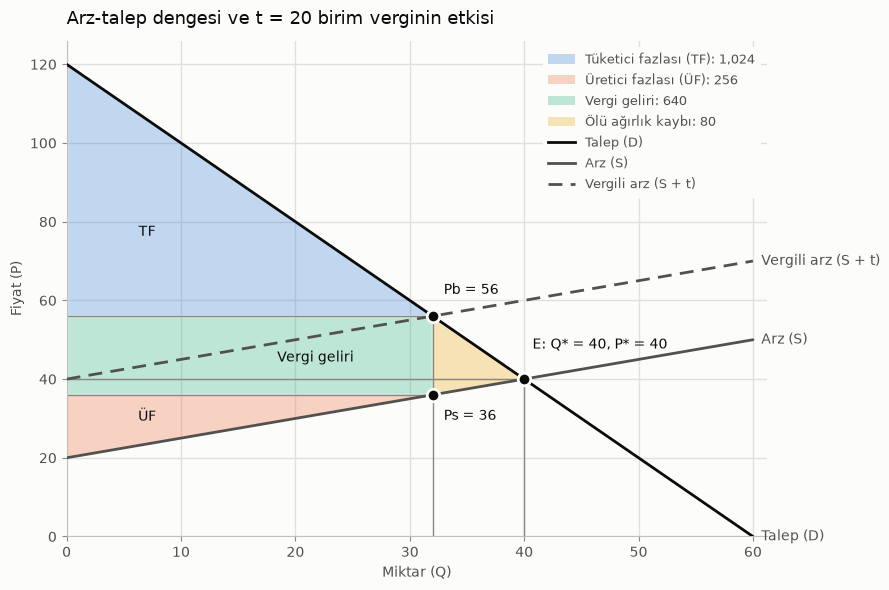

In [4]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, Polygon
from matplotlib.lines import Line2D

# Grafik renkleri: alanlar kategori rengi taşır, metinler her zaman nötr mürekkep rengindedir.
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
COLORS = {
    "consumer": "#2a78d6",   # Tüketici fazlası
    "producer": "#eb6834",   # Üretici fazlası
    "revenue": "#1baf7a",    # Vergi geliri
    "deadweight": "#eda100", # Ölü ağırlık kaybı
}


def style_axes(ax, xlabel: str, ylabel: str, title: str) -> None:
    """Eksenleri sade bir görünüme getirir: ince ızgara, soluk eksen çizgileri."""
    ax.set_facecolor(SURFACE)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.grid(color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_MUTED, labelcolor=INK_SECONDARY)
    ax.set_xlabel(xlabel, color=INK_SECONDARY)
    ax.set_ylabel(ylabel, color=INK_SECONDARY)
    ax.set_title(title, color=INK, loc="left", fontsize=13, pad=12)


def plot_market(market: LinearMarket, tax: float):
    """Arz, talep, vergili arz eğrilerini ve refah alanlarını çizer."""
    eq = market.equilibrium()
    tx = market.apply_unit_tax(tax)
    q_max = market.alpha / market.beta  # Talebin sıfırlandığı miktar
    qt, pb, ps = tx.quantity, tx.buyer_price, tx.seller_price

    fig, ax = plt.subplots(figsize=(9, 6), facecolor=SURFACE)
    style_axes(ax, "Miktar (Q)", "Fiyat (P)", f"Arz-talep dengesi ve t = {tax:g} birim verginin etkisi")

    areas = {
        "consumer": [(0, market.alpha), (0, pb), (qt, pb)],
        "revenue": [(0, pb), (qt, pb), (qt, ps), (0, ps)],
        "producer": [(0, ps), (qt, ps), (0, market.gamma)],
        "deadweight": [(qt, pb), (eq.quantity, eq.price), (qt, ps)],
    }
    for key, corners in areas.items():
        # Kenardaki yüzey renginde 2px çizgi, bitişik alanlar arasında boşluk bırakır.
        ax.add_patch(Polygon(corners, closed=True, facecolor=COLORS[key], alpha=0.28,
                             edgecolor=SURFACE, linewidth=2, zorder=1))

    q_line = [0, q_max]
    ax.plot(q_line, [market.demand_price(q) for q in q_line], color=INK, linewidth=2,
            solid_capstyle="round", zorder=3)
    ax.plot(q_line, [market.supply_price(q) for q in q_line], color=INK_SECONDARY, linewidth=2,
            solid_capstyle="round", zorder=3)
    ax.plot(q_line, [market.supply_price(q) + tax for q in q_line], color=INK_SECONDARY,
            linewidth=2, linestyle=(0, (5, 3)), zorder=3)

    # Eğri sonlarına doğrudan etiketler
    end_labels = [
        (market.demand_price(q_max), "Talep (D)"),
        (market.supply_price(q_max), "Arz (S)"),
        (market.supply_price(q_max) + tax, "Vergili arz (S + t)"),
    ]
    for y, label in end_labels:
        ax.annotate(label, (q_max, y), xytext=(6, 0), textcoords="offset points",
                    va="center", color=INK_SECONDARY, fontsize=10, annotation_clip=False)

    # Alan içi etiketler (alan yeterince büyükse)
    ax.text(qt * 0.22, (market.alpha + 2 * pb) / 3, "TF", color=INK, fontsize=10, ha="center", va="center")
    label_q = qt * 0.68  # Etiketi P* kılavuz çizgisi ile vergili arz eğrisinin arasına yerleştir
    ax.text(label_q, (eq.price + market.supply_price(label_q) + tax) / 2, "Vergi geliri", color=INK,
            fontsize=10, ha="center", va="center")
    ax.text(qt * 0.22, (market.gamma + 2 * ps) / 3, "ÜF", color=INK, fontsize=10, ha="center", va="center")

    # Önemli noktalar: yüzey renginde halka, işaretçiyi çizgilerden ayırır.
    points = [(eq.quantity, eq.price, f"E: Q* = {eq.quantity:g}, P* = {eq.price:g}", (6, 22)),
              (qt, pb, f"Pb = {pb:g}", (8, 16)),
              (qt, ps, f"Ps = {ps:g}", (8, -18))]
    for x, y, label, offset in points:
        ax.plot(x, y, "o", markersize=9, color=INK, markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)
        ax.annotate(label, (x, y), xytext=offset, textcoords="offset points", color=INK, fontsize=10)

    # Fiyat ve miktar eksenlerine kılavuz çizgiler
    for y in (eq.price, pb, ps):
        ax.plot([0, qt if y != eq.price else eq.quantity], [y, y], color=INK_MUTED, linewidth=1, zorder=2)
    ax.plot([qt, qt], [0, pb], color=INK_MUTED, linewidth=1, zorder=2)
    ax.plot([eq.quantity, eq.quantity], [0, eq.price], color=INK_MUTED, linewidth=1, zorder=2)

    ax.set_xlim(0, q_max * 1.02)
    ax.set_ylim(0, market.alpha * 1.05)

    legend_items = [
        Patch(facecolor=COLORS["consumer"], alpha=0.28, label=f"Tüketici fazlası (TF): {tx.consumer_surplus:,.0f}"),
        Patch(facecolor=COLORS["producer"], alpha=0.28, label=f"Üretici fazlası (ÜF): {tx.producer_surplus:,.0f}"),
        Patch(facecolor=COLORS["revenue"], alpha=0.28, label=f"Vergi geliri: {tx.tax_revenue:,.0f}"),
        Patch(facecolor=COLORS["deadweight"], alpha=0.28, label=f"Ölü ağırlık kaybı: {tx.deadweight_loss:,.0f}"),
        Line2D([], [], color=INK, linewidth=2, label="Talep (D)"),
        Line2D([], [], color=INK_SECONDARY, linewidth=2, label="Arz (S)"),
        Line2D([], [], color=INK_SECONDARY, linewidth=2, linestyle=(0, (5, 3)), label="Vergili arz (S + t)"),
    ]
    legend = ax.legend(handles=legend_items, loc="upper right", fontsize=9.5, facecolor=SURFACE,
                       edgecolor=SURFACE, framealpha=1)
    for text in legend.get_texts():
        text.set_color(INK_SECONDARY)

    fig.tight_layout()
    return fig


plot_market(market, example_tax)
plt.show()

### Grafik 2: Vergi Oranı, Vergi Geliri ve Refah Kaybı

Vergi arttıkça gelir önce artar, sonra azalır (Laffer eğrisi mantığı); ölü ağırlık kaybı ise verginin karesiyle büyür. Bu yüzden vergiyi iki katına çıkarmak, refah kaybını yaklaşık dört katına çıkarır.

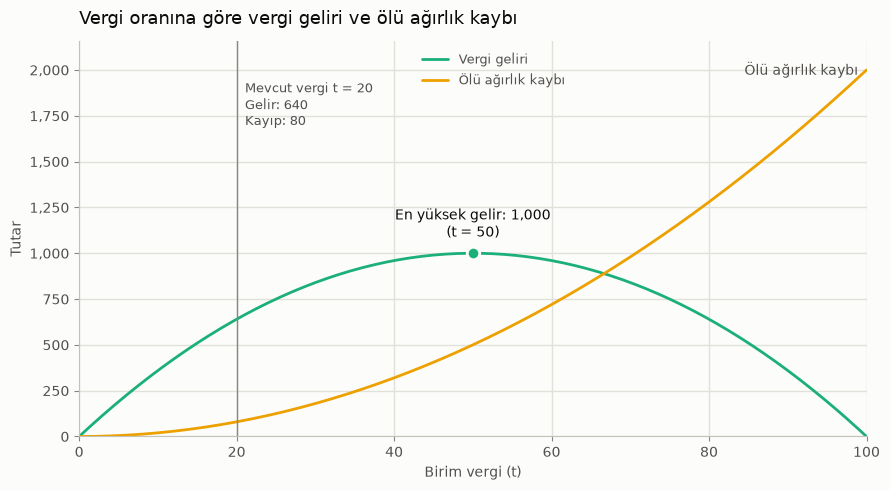

In [5]:
def plot_tax_sensitivity(market: LinearMarket, current_tax: float, steps: int = 200):
    """Farklı vergi oranları için vergi gelirini ve ölü ağırlık kaybını çizer."""
    max_tax = market.alpha - market.gamma  # Bu noktada piyasa kapanır
    taxes = [max_tax * i / steps for i in range(steps + 1)]
    outcomes = [market.apply_unit_tax(t) for t in taxes]
    revenue = [o.tax_revenue for o in outcomes]
    deadweight = [o.deadweight_loss for o in outcomes]

    fig, ax = plt.subplots(figsize=(9, 5), facecolor=SURFACE)
    style_axes(ax, "Birim vergi (t)", "Tutar", "Vergi oranına göre vergi geliri ve ölü ağırlık kaybı")

    ax.plot(taxes, revenue, color=COLORS["revenue"], linewidth=2, solid_capstyle="round", label="Vergi geliri")
    ax.plot(taxes, deadweight, color=COLORS["deadweight"], linewidth=2, solid_capstyle="round",
            label="Ölü ağırlık kaybı")

    # Doğrudan etiketler: gelir zirvesinde, kayıp eğrisinin sonunda
    t_best = market.revenue_maximizing_tax()
    best = market.apply_unit_tax(t_best)
    ax.plot(t_best, best.tax_revenue, "o", markersize=9, color=COLORS["revenue"],
            markeredgecolor=SURFACE, markeredgewidth=2, zorder=4)
    ax.annotate(f"En yüksek gelir: {best.tax_revenue:,.0f}\n(t = {t_best:g})", (t_best, best.tax_revenue),
                xytext=(0, 12), textcoords="offset points", ha="center", color=INK, fontsize=10)
    ax.annotate("Ölü ağırlık kaybı", (taxes[-1], deadweight[-1]), xytext=(-6, 0),
                textcoords="offset points", ha="right", va="center", color=INK_SECONDARY, fontsize=10)

    # Mevcut vergi oranı
    current = market.apply_unit_tax(current_tax)
    ax.axvline(current_tax, color=INK_MUTED, linewidth=1, zorder=2)
    ax.annotate(f"Mevcut vergi t = {current_tax:g}\nGelir: {current.tax_revenue:,.0f}\n"
                f"Kayıp: {current.deadweight_loss:,.0f}",
                (current_tax, max(deadweight) * 0.97), xytext=(6, 0), textcoords="offset points",
                va="top", color=INK_SECONDARY, fontsize=9.5)

    ax.set_xlim(0, max_tax)
    ax.set_ylim(0, max(max(revenue), max(deadweight)) * 1.08)
    ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
    legend = ax.legend(loc="upper left", bbox_to_anchor=(0.42, 1.0), frameon=False, fontsize=9.5)
    for text in legend.get_texts():
        text.set_color(INK_SECONDARY)

    fig.tight_layout()
    return fig


plot_tax_sensitivity(market, example_tax)
plt.show()

### Kullanıcıdan Girdi Alarak Piyasa Analizi

Şimdi kendi piyasa parametrelerinizi girerek analizi tekrarlayabilirsiniz. Hatalı bir değer girildiğinde program değeri yeniden ister.

In [ ]:
def read_float(prompt: str) -> float:
    """Kullanıcıdan geçerli bir sayı alınana kadar girdi ister (ondalık ayırıcı olarak virgül de kabul edilir)."""
    while True:
        raw = input(prompt).strip().replace(",", ".")
        try:
            return float(raw)
        except ValueError:
            print("  Geçersiz sayı, lütfen tekrar deneyin.")


print("Lütfen piyasa parametrelerini giriniz (ters talep: P = alpha - beta*Q, ters arz: P = gamma + delta*Q):")
while True:
    try:
        user_market = LinearMarket(
            alpha=read_float("Talebin en yüksek fiyatı, alpha (örn. 120): "),
            beta=read_float("Talep eğimi, beta (örn. 2): "),
            gamma=read_float("Arzın en düşük fiyatı, gamma (örn. 20): "),
            delta=read_float("Arz eğimi, delta (örn. 0.5): "),
        )
        user_tax = read_float("Birim vergi, t (örn. 20): ")
        user_market.apply_unit_tax(user_tax)  # Vergiyi doğrula
        break
    except ValueError as error:
        print(f"  Hata: {error} Lütfen değerleri yeniden giriniz.\n")

print()
print(format_report(user_market, user_tax))
plot_market(user_market, user_tax)
plt.show()